# Sensitivity analysis — inventory multiplier M

Scenario: cascading floods of the three basins (Saigon, Siem Bok, St. Sen).  Sweep over

- **M** ∈ {0.5, 1, 2} — multiplier on each sector's inventory target b_{j,k} (table S1).
- **D** ∈ {4, 8, 12} d — disruption duration.
- **τ** = time_lag / D ∈ {0, 0.5, 1, 1.5, 2} — normalized basin-lag.

Baseline = M = 1.  Restoration time held at T = 4 d.  All runs use `np.random.seed=42` so the SC-network is identical across combinations; variation is 100 % from (M, D, τ).

In [46]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path('data/sensitivity')
FIGDIR = Path('figures/generated')
FIGDIR.mkdir(parents=True, exist_ok=True)

# same seed (42)
csvs = [OUT / 'sensitivity_inventory.csv',
        OUT / 'sensitivity_inventory_extended.csv']
df = pd.concat([pd.read_csv(p) for p in csvs if p.exists()], ignore_index=True)

df = (df.drop_duplicates(subset=['duration', 'inventory_multiplier',
                                 'inventory_restoration_time', 'tau', 'seed'])
        .sort_values(['duration', 'inventory_multiplier', 'tau'])
        .reset_index(drop=True))

print(f'{len(df)} rows loaded from {[p.name for p in csvs if p.exists()]}')
df[['duration', 'inventory_multiplier', 'tau', 'time_lag', 'household_loss']]

63 rows loaded from ['sensitivity_inventory.csv', 'sensitivity_inventory_extended.csv']


,duration,inventory_multiplier,tau,time_lag,household_loss
0,4,0.5,0.0,0,12.579872
1,4,0.5,0.5,2,22.826688
2,4,0.5,1.0,4,48.655238
3,4,0.5,1.5,6,24.583183
4,4,0.5,2.0,8,51.031678
...,...,...,...,...,...
58,12,2.0,1.0,12,9.675642
59,12,2.0,1.5,18,9.232346
60,12,2.0,2.0,24,11.065730
61,12,2.0,2.5,30,6.780499


## Plot — household loss vs τ, one subplot per D, one line per M

Replicates notebook 03's left-panel shape but across the three inventory multipliers.

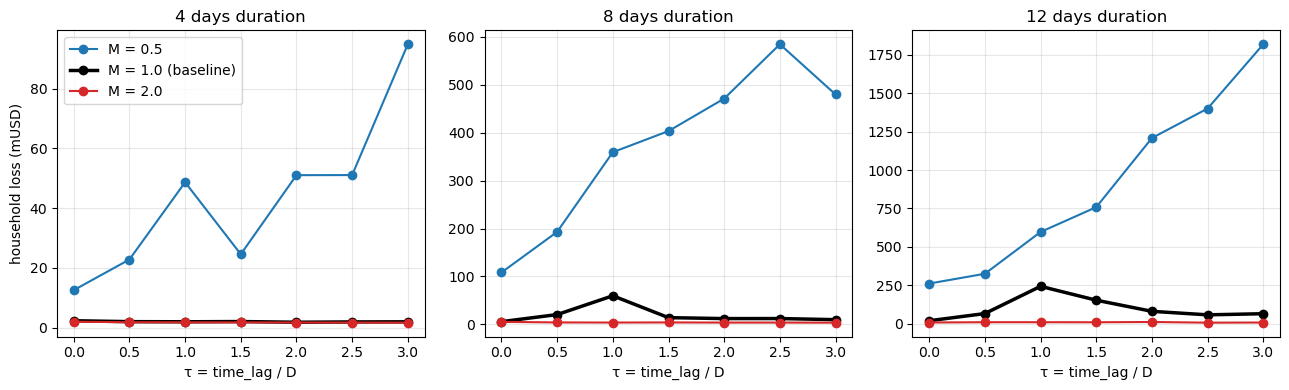

In [47]:
durations = sorted(df['duration'].unique())
m_colors = {0.5: '#1f77b4', 1.0: '#000000', 2.0: '#d62728'}

fig, axes = plt.subplots(1, len(durations), figsize=(13, 4), sharey=False)

for ax, D in zip(axes, durations):
    sub = df[df['duration'] == D]
    for M, g in sub.groupby('inventory_multiplier'):
        g = g.sort_values('tau')
        label = f'M = {M}' + (' (baseline)' if M == 1.0 else '')
        ax.plot(g['tau'], g['household_loss'], 'o-',
                color=m_colors.get(M, None), label=label,
                lw=(2.5 if M == 1.0 else 1.5))
    ax.set_title(f'{D} days duration')
    ax.set_xlabel('τ = time_lag / D')
    ax.set_xticks(sorted(df['tau'].unique()))
    ax.grid(alpha=0.3)

axes[0].set_ylabel('household loss (mUSD)')
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGDIR / 'fig_sensitivity_inventory_M.png', dpi=100, bbox_inches='tight')
plt.show()

## Plot — household loss vs τ, one subplot per D, one line per T

Same structure as the M plot but varying the inventory restoration time T = 1/ρ instead of the buffer size.  M = 1 (baseline).  Needs the T sweep:

```bash
bash scripts/sensitivity_inventory_T.sh
```

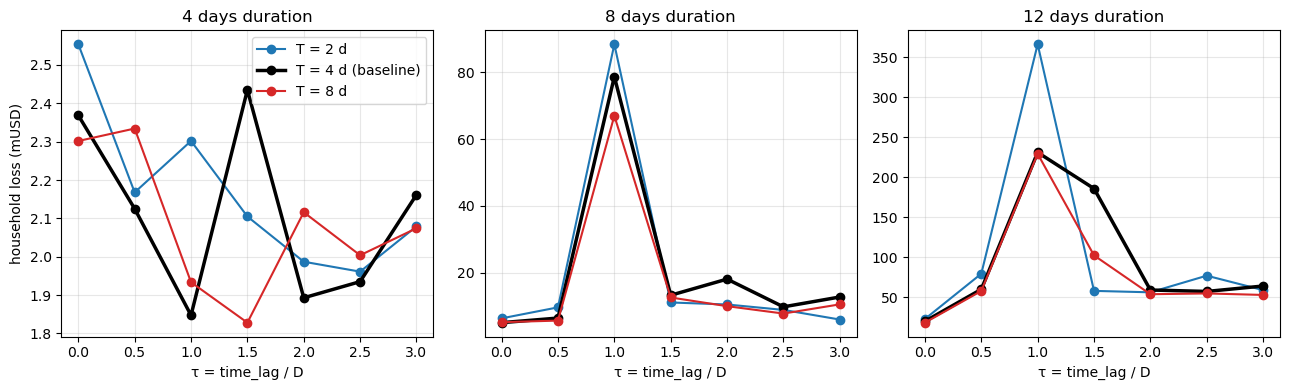

In [48]:
t_csv = OUT / 'sensitivity_inventory_T.csv'
if not t_csv.exists():
    print('sensitivity_inventory_T.csv not found yet.  Run the T sweep first.')
else:
    t_df = pd.read_csv(t_csv)
    # Baseline T=4, M=1 rows already live in df (main M sweep); merge them in
    baseline_t4 = df[(df['inventory_multiplier'] == 1.0)
                     & (df['inventory_restoration_time'] == 4.0)]
    t_all = pd.concat([t_df, baseline_t4], ignore_index=True)
    t_all = (t_all.drop_duplicates(subset=['duration', 'inventory_restoration_time',
                                           'tau', 'seed'])
                  .sort_values(['duration', 'inventory_restoration_time', 'tau']))

    durations = sorted(t_all['duration'].unique())
    t_colors = {2.0: '#1f77b4', 4.0: '#000000', 8.0: '#d62728'}

    fig, axes = plt.subplots(1, len(durations), figsize=(13, 4), sharey=False)
    for ax, D in zip(axes, durations):
        sub = t_all[t_all['duration'] == D]
        for T, g in sub.groupby('inventory_restoration_time'):
            g = g.sort_values('tau')
            label = f'T = {int(T)} d' + (' (baseline)' if T == 4.0 else '')
            ax.plot(g['tau'], g['household_loss'], 'o-',
                    color=t_colors.get(T, None), label=label,
                    lw=(2.5 if T == 4.0 else 1.5))
        ax.set_title(f'{D} days duration')
        ax.set_xlabel('τ = time_lag / D')
        ax.set_xticks(sorted(t_all['tau'].unique()))
        ax.grid(alpha=0.3)

    axes[0].set_ylabel('household loss (mUSD)')
    axes[0].legend()
    plt.tight_layout()
    plt.savefig(FIGDIR / 'fig_sensitivity_inventory_T.png', dpi=100, bbox_inches='tight')
    plt.show()

## Summary — losses by (D, M, τ)

In [49]:
(df.pivot_table(index=['duration', 'inventory_multiplier'],
                columns='tau', values='household_loss')
   .round(2))

tau                               0.0     0.5     1.0     1.5      2.0  \
duration inventory_multiplier                                            
4        0.5                    12.58   22.83   48.66   24.58    51.03   
         1.0                     2.35    2.05    2.00    2.08     1.85   
         2.0                     2.03    1.85    1.82    1.80     1.75   
8        0.5                   108.30  193.04  359.20  403.29   471.01   
         1.0                     5.77   20.53   59.75   14.12    12.18   
         2.0                     5.31    4.14    3.91    4.14     3.87   
12       0.5                   261.47  325.09  597.13  758.76  1208.81   
         1.0                    19.24   66.01  243.25  153.03    80.56   
         2.0                     7.81    9.60    9.68    9.23    11.07   

tau                                2.5      3.0  
duration inventory_multiplier                    
4        0.5                     51.06    94.80  
         1.0                      1.95     1.99  
         2.0                      1.74     1.71  
8        0.5                    584.33   479.58  
         1.0                     12.24     9.93  
         2.0                      3.89     3.67  
12       0.5                   1400.74  1819.27  
         1.0                     57.68    65.07  
         2.0                      6.78     7.73

## Per-sector inventory sensitivity — which sector is the bottleneck?

For each disruption duration **D ∈ {4, 8, 12} d** at **τ = 0** (simultaneous cascade), halve ONE sector's b_{j,k} at a time (others stay at baseline).  Dashed horizontal line = baseline (all M=1) at the same (D, τ).

Taller bar ⇒ that sector's inventory buffer is a bigger resilience bottleneck.  Needs the per-sector sweep to be run:

```bash
bash scripts/sensitivity_inventory_per_sector.sh
```

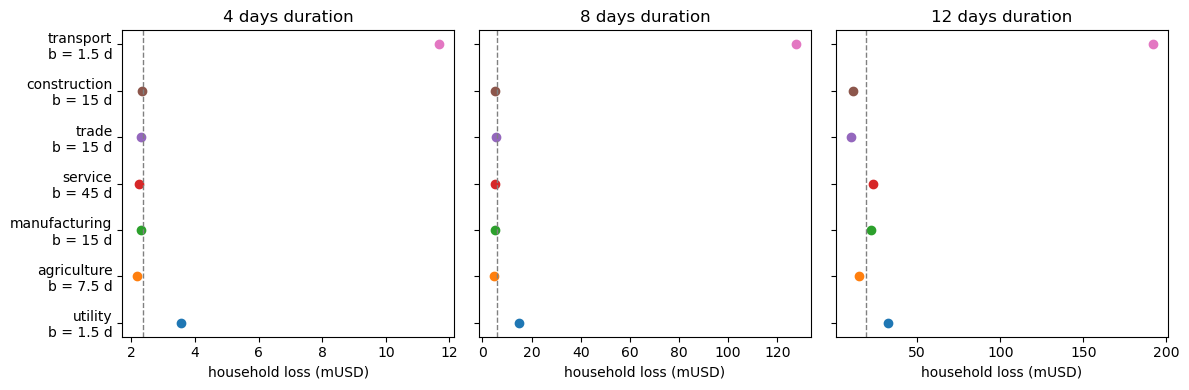

In [50]:
sec_csv = OUT / 'sensitivity_inventory_per_sector.csv'
if not sec_csv.exists():
    print('sensitivity_inventory_per_sector.csv not found yet.')
else:
    sec = pd.read_csv(sec_csv)
    sec = sec[sec['tau'] == 0]

    target_col = df.get('target_sector', pd.Series([''] * len(df))).fillna('')
    baselines = {}
    for D in sorted(sec['duration'].unique()):
        bl = df[(df['duration'] == D) & (df['tau'] == 0)
                & (df['inventory_multiplier'] == 1.0) & (target_col == '')]
        baselines[D] = bl['household_loss'].iloc[0] if len(bl) else None

    sectors = ['utility', 'agriculture', 'manufacturing', 'service',
               'trade', 'construction', 'transport']
    sectors = [s for s in sectors if s in sec['target_sector'].values]
    b_baseline = {'utility': 3, 'agriculture': 15, 'manufacturing': 30,
                  'service': 90, 'trade': 30, 'construction': 30, 'transport': 3}
    colors = plt.cm.tab10(range(len(sectors)))
    durations = sorted(sec['duration'].unique())

    fig, axes = plt.subplots(1, len(durations), figsize=(12, 4), sharey=True)
    for ax, D in zip(axes, durations):
        sub = sec[sec['duration'] == D].set_index('target_sector').reindex(sectors)
        for i, s in enumerate(sectors):
            ax.scatter(sub.loc[s, 'household_loss'], i, color=colors[i])
        if baselines[D] is not None:
            ax.axvline(baselines[D], ls='--', color='grey', lw=1)
        ax.set_title(f'{D} days duration')
        ax.set_xlabel('household loss (mUSD)')

    axes[0].set_yticks(range(len(sectors)))
    axes[0].set_yticklabels([f'{s}\nb = {b_baseline[s] * 0.5:g} d' for s in sectors])
    plt.tight_layout()
    plt.savefig(FIGDIR / 'fig_sensitivity_inventory_per_sector.png', dpi=100, bbox_inches='tight')
    plt.show()

## Policy scenario — protect the bottleneck sectors

What if we **halve all sector buffers EXCEPT** the two bottlenecks (utility, transport)?  Comparison vs the uniform scenarios M=1 (baseline) and M=0.5 (uniform halving).  Needs:

```bash
bash scripts/sensitivity_inventory_protect.sh
```

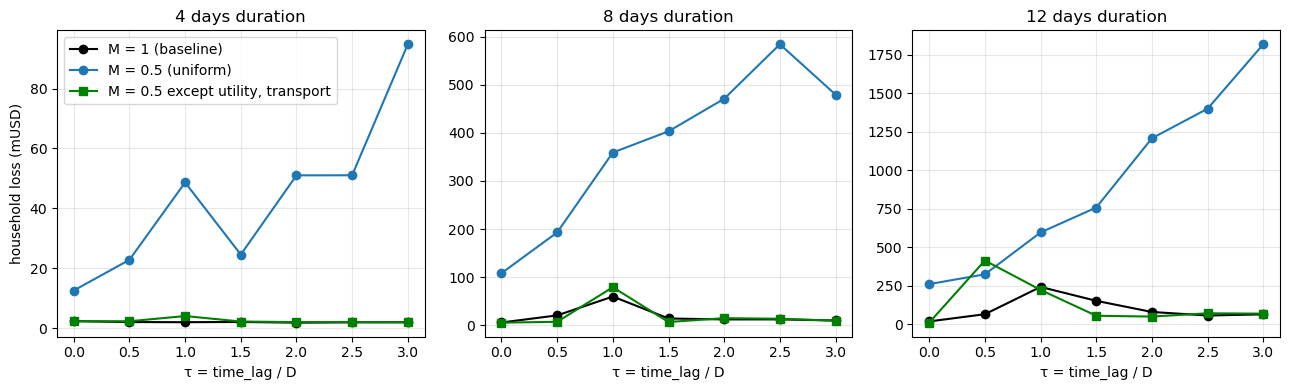

In [51]:
prot_csv = OUT / 'sensitivity_inventory_protect.csv'
if not prot_csv.exists():
    print('sensitivity_inventory_protect.csv not found yet.')
else:
    prot = pd.read_csv(prot_csv)
    durations = sorted(prot['duration'].unique())

    fig, axes = plt.subplots(1, len(durations), figsize=(13, 4), sharey=False)
    for ax, D in zip(axes, durations):
        g = df[(df['duration'] == D) & (df['inventory_multiplier'] == 1.0)].sort_values('tau')
        ax.plot(g['tau'], g['household_loss'], 'o-', color='#000000',
                label='M = 1 (baseline)')
        g = df[(df['duration'] == D) & (df['inventory_multiplier'] == 0.5)].sort_values('tau')
        ax.plot(g['tau'], g['household_loss'], 'o-', color='#1f77b4',
                label='M = 0.5 (uniform)')
        gp = prot[prot['duration'] == D].sort_values('tau')
        ax.plot(gp['tau'], gp['household_loss'], 's-', color='green',
                label='M = 0.5 except utility, transport')
        ax.set_title(f'{D} days duration')
        ax.set_xlabel('τ = time_lag / D')
        ax.set_xticks(sorted(prot['tau'].unique()))
        ax.grid(alpha=0.3)

    axes[0].set_ylabel('household loss (mUSD)')
    axes[0].legend()
    plt.tight_layout()
    plt.savefig(FIGDIR / 'fig_sensitivity_inventory_protect.png', dpi=100, bbox_inches='tight')
    plt.show()